<a href="https://colab.research.google.com/github/farihamim11/desktop-tutorial/blob/main/SMS_main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Detection — Backtracking + Multi-Model ML + LLM (v3)



In [1]:
!pip -q install nltk wordcloud scikit-learn joblib anthropic tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 6.5 MB/s eta 0:00:00


In [2]:
import re, os, json, time, string, getpass, warnings, threading
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from tqdm.auto import tqdm

from scipy.sparse import hstack, csr_matrix
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC

for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 1. Load the dataset

Put `SMS.csv` / `spam.csv` in the Colab working directory, or upload it when asked.
The loader auto-detects which column is the label and which is the message.

In [3]:
candidates = [f for f in ["SMS.csv", "spam.csv", "sms.csv"] if os.path.exists(f)]
if candidates:
    filename = candidates[0]
else:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
print("Using file:", filename)

raw = pd.read_csv(filename, encoding="latin-1").iloc[:, :2].copy()
raw.columns = ["a", "b"]

# Auto-detect column order (label first = UCI/Kaggle format)
if raw["a"].astype(str).str.lower().str.strip().isin(["ham", "spam"]).mean() > 0.9:
    raw = raw.rename(columns={"a": "label", "b": "message"})
else:
    raw = raw.rename(columns={"a": "message", "b": "label"})

raw["label"] = raw["label"].astype(str).str.lower().str.strip().map({"ham": 0, "spam": 1})
df = (raw.dropna(subset=["message", "label"])
         .drop_duplicates(subset=["message"])
         .reset_index(drop=True))
df["label"] = df["label"].astype(int)

print("Dataset shape:", df.shape)
print(df["label"].value_counts().rename(index={0: "ham", 1: "spam"}))

Saving spam.csv to spam.csv
Using file: spam.csv
Dataset shape: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


## 2. Basic EDA

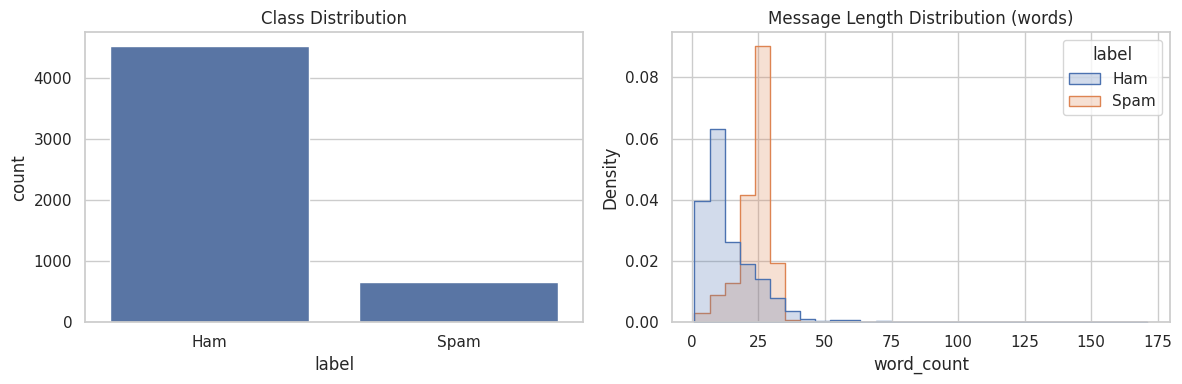

       char_count  word_count
label                        
ham          70.5        14.1
spam        137.9        23.7


In [4]:
df["char_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()
label_name = df["label"].map({0: "Ham", 1: "Spam"})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=label_name, ax=ax[0])
ax[0].set_title("Class Distribution")
sns.histplot(data=df, x="word_count", hue=label_name, bins=30, element="step",
             stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("Message Length Distribution (words)")
plt.tight_layout()
plt.show()

print(df.groupby("label")[["char_count", "word_count"]].mean().rename(index={0: "ham", 1: "spam"}).round(1))

## 3. Text preprocessing

In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " URL ", text)
    text = re.sub(r"\S+@\S+", " EMAIL ", text)
    text = re.sub(r"\d+", " NUMBER ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words]
    return " ".join(tokens)

df["clean_message"] = df["message"].apply(clean_text)
df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry NUMBER wkly comp win fa cup final t...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


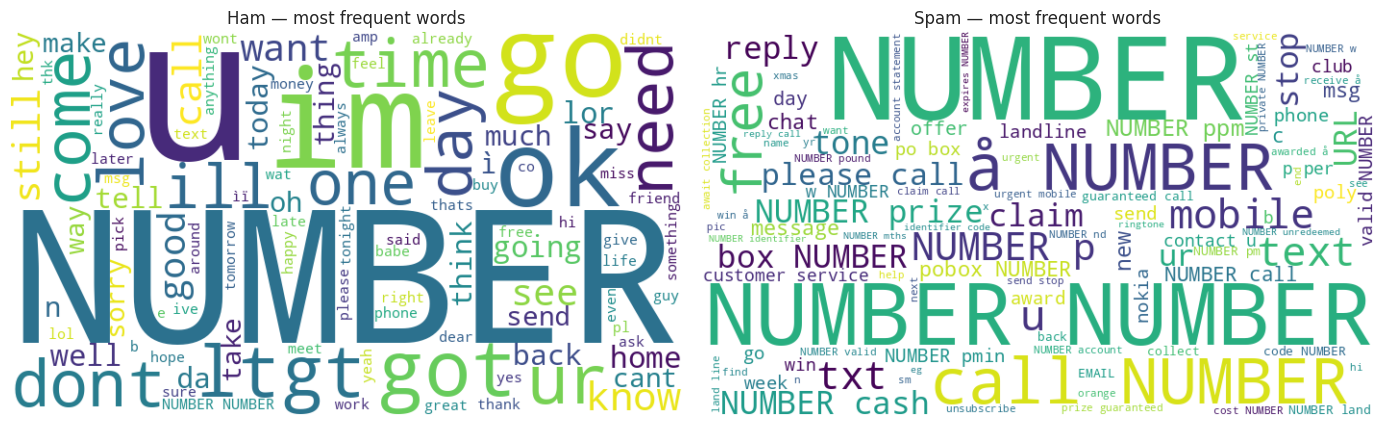

In [6]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lab, name) in zip(axes, [(0, "Ham"), (1, "Spam")]):
    text = " ".join(df.loc[df["label"] == lab, "clean_message"])
    wc = WordCloud(width=700, height=400, background_color="white", max_words=100).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{name} — most frequent words")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Handcrafted SMS features



In [7]:
def extract_features(text):
    text = str(text)
    low = text.lower()
    words = text.split()
    return {
        "char_len": len(text),
        "word_len": len(words),
        "digit_count": sum(c.isdigit() for c in text),
        "upper_count": sum(c.isupper() for c in text),
        "exclamation_count": text.count("!"),
        "question_count": text.count("?"),
        "currency_count": sum(text.count(x) for x in ["$", "£", "€"]),
        "url_count": len(re.findall(r"https?://|www\.", low)),
        "phone_like": int(bool(re.search(r"(?:\+?\d[\d\s-]{7,}\d)", text))),
        "has_free": int(bool(re.search(r"\bfree\b", low))),
        "has_win": int(bool(re.search(r"\b(win|winner|won)\b", low))),
        "has_call": int(bool(re.search(r"\b(call|contact)\b", low))),
    }

feature_df = pd.DataFrame(df["message"].apply(extract_features).tolist())
feature_names = list(feature_df.columns)

# One master table: label + raw text + cleaned text + handcrafted features
data = pd.concat([df[["label", "message", "clean_message"]], feature_df], axis=1)

print("Candidate features:", feature_names)
display(feature_df.head())

Candidate features: ['char_len', 'word_len', 'digit_count', 'upper_count', 'exclamation_count', 'question_count', 'currency_count', 'url_count', 'phone_like', 'has_free', 'has_win', 'has_call']


,char_len,word_len,digit_count,upper_count,exclamation_count,question_count,currency_count,url_count,phone_like,has_free,has_win,has_call
0,111,20,0,3,0,0,0,0,0,0,0,0
1,29,6,0,2,0,0,0,0,0,0,0,0
2,155,28,25,10,0,0,0,0,1,1,1,0
3,49,11,0,2,0,0,0,0,0,0,0,0
4,61,13,0,2,0,0,0,0,0,0,0,0


## 5. Train / validation / test split

| Split | Used for |
|---|---|
| **Train (70%)** | fitting models |
| **Validation (15%)** | the backtracking search |
| **Test (15%)** | touched **once**, for final reporting (and the LLM comparison) |

Model *selection* uses cross-validation on train+val (`dev_df`), never the test set.

In [8]:
train_df, temp_df = train_test_split(data, test_size=0.30, random_state=RANDOM_STATE, stratify=data["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df["label"])
dev_df = pd.concat([train_df, val_df])          # train + validation (for CV / final refit)

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10s}: {len(part):5d} messages | spam = {part['label'].mean():.1%}")

train     :  3618 messages | spam = 12.6%
validation:   775 messages | spam = 12.6%
test      :   776 messages | spam = 12.6%


## 6. Backtracking Feature Selection



In [9]:
# TF-IDF is fixed while backtracking searches over handcrafted features.
bt_tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=1, sublinear_tf=True)
Xtr_tfidf = bt_tfidf.fit_transform(train_df["clean_message"])
Xv_tfidf = bt_tfidf.transform(val_df["clean_message"])

bt_scaler = MinMaxScaler().fit(train_df[feature_names])
Ftr = bt_scaler.transform(train_df[feature_names])
Fv = bt_scaler.transform(val_df[feature_names])
y_tr, y_v = train_df["label"].values, val_df["label"].values

MAX_SELECTED = 6          # raise to 7+ for a deeper (slower) search
best_subset, best_score = [], -1.0
nodes_visited = 0
feature_cache = {}        # tuple(subset) -> validation spam F1

def evaluate_subset(subset):
    key = tuple(subset)
    if key in feature_cache:
        return feature_cache[key]
    if subset:
        cols = [feature_names.index(f) for f in subset]
        Xtr = hstack([Xtr_tfidf, csr_matrix(Ftr[:, cols])], format="csr")
        Xv = hstack([Xv_tfidf, csr_matrix(Fv[:, cols])], format="csr")
    else:
        Xtr, Xv = Xtr_tfidf, Xv_tfidf
    model = LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE)
    model.fit(Xtr, y_tr)
    score = f1_score(y_v, model.predict(Xv), pos_label=1)
    feature_cache[key] = score
    return score

def backtrack(index, selected):
    global best_subset, best_score, nodes_visited
    nodes_visited += 1

    score = evaluate_subset(selected)
    better = score > best_score + 1e-9
    tie_but_smaller = abs(score - best_score) <= 1e-9 and len(selected) < len(best_subset)
    if better or tie_but_smaller:
        best_score, best_subset = score, selected.copy()

    if index == len(feature_names) or len(selected) == MAX_SELECTED:   # pruning
        return

    selected.append(feature_names[index])      # choice 1: include
    backtrack(index + 1, selected)
    selected.pop()                             # <-- backtrack (undo)

    backtrack(index + 1, selected)             # choice 2: exclude

t0 = time.time()
backtrack(0, [])
bt_time = time.time() - t0

print("Best handcrafted subset :", best_subset)
print("Validation Spam F1      :", round(best_score, 4))
print("Baseline (TF-IDF only)  :", round(feature_cache[()], 4))
print("Recursion nodes visited :", nodes_visited)
print("Distinct subsets trained:", len(feature_cache), "of", 2 ** len(feature_names), "possible")
print(f"Search time             : {bt_time:.1f}s")

Best handcrafted subset : ['upper_count', 'currency_count', 'url_count', 'phone_like']
Validation Spam F1      : 0.9479
Baseline (TF-IDF only)  : 0.9016
Recursion nodes visited : 5019
Distinct subsets trained: 2510 of 4096 possible
Search time             : 117.1s


Top 10 subsets found by backtracking:


,size,features,val_f1
0,4,"upper_count, currency_count, url_count, phone_...",0.947917
1,4,"currency_count, url_count, phone_like, has_call",0.947917
2,5,"upper_count, question_count, currency_count, u...",0.947917
3,5,"upper_count, currency_count, url_count, phone_...",0.947917
4,5,"upper_count, currency_count, url_count, phone_...",0.947917
5,5,"exclamation_count, currency_count, url_count, ...",0.947917
6,5,"question_count, currency_count, url_count, pho...",0.947917
7,6,"word_len, digit_count, currency_count, url_cou...",0.947917
8,6,"digit_count, upper_count, currency_count, url_...",0.947917
9,6,"digit_count, upper_count, currency_count, url_...",0.947917


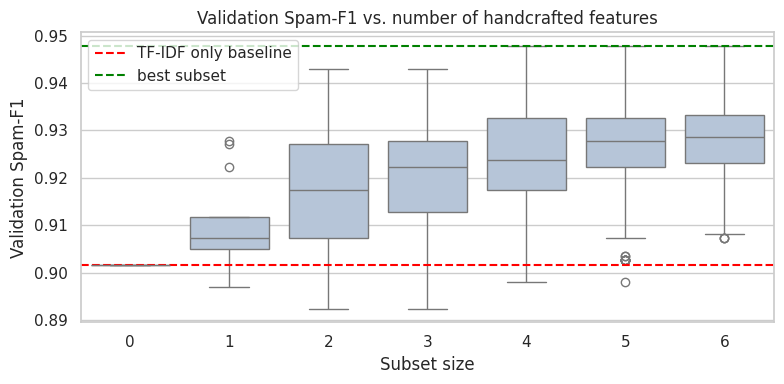

In [10]:
bt_df = pd.DataFrame([{"size": len(k), "features": ", ".join(k) or "(none)", "val_f1": v}
                      for k, v in feature_cache.items()])

print("Top 10 subsets found by backtracking:")
display(bt_df.sort_values(["val_f1", "size"], ascending=[False, True]).head(10).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=bt_df, x="size", y="val_f1", color="lightsteelblue", ax=ax)
ax.axhline(feature_cache[()], color="red", ls="--", label="TF-IDF only baseline")
ax.axhline(best_score, color="green", ls="--", label="best subset")
ax.set_title("Validation Spam-F1 vs. number of handcrafted features")
ax.set_xlabel("Subset size")
ax.set_ylabel("Validation Spam-F1")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Final hybrid pipeline + hyper-parameter tuning



In [11]:
TFIDF_PARAMS = dict(max_features=5000, ngram_range=(1, 2), min_df=1, sublinear_tf=True)

def make_pipeline(model):
    transformers = [("tfidf", TfidfVectorizer(**TFIDF_PARAMS), "clean_message")]
    if best_subset:
        transformers.append(("hand", MinMaxScaler(), list(best_subset)))
    prep = ColumnTransformer(transformers, sparse_threshold=1.0)   # always keep sparse output
    return Pipeline([("prep", prep), ("clf", model)])

def get_models():
    return {
        "Linear SVM": LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
        "Logistic Regression": LogisticRegression(C=2.0, max_iter=2000, class_weight="balanced",
                                                  random_state=RANDOM_STATE),
        "Multinomial NB": MultinomialNB(alpha=0.5),
        "Complement NB": ComplementNB(alpha=0.5),
        "SGD Classifier": SGDClassifier(loss="modified_huber", alpha=1e-5, class_weight="balanced",
                                        max_iter=2000, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=20,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "Extra Trees": ExtraTreesClassifier(n_estimators=250, class_weight="balanced",
                                            random_state=RANDOM_STATE),
        "Soft Voting (LR+NB+RF)": VotingClassifier(
            estimators=[
                ("lr", LogisticRegression(C=2.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
                ("nb", MultinomialNB(alpha=0.5)),
                ("rf", RandomForestClassifier(n_estimators=200, max_depth=20, class_weight="balanced",
                                              random_state=RANDOM_STATE)),
            ],
            voting="soft"),
    }

tune_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    "Linear SVM": (LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
                   {"clf__C": [0.1, 0.3, 1, 3, 10]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
                            {"clf__C": [0.5, 1, 2, 5, 10, 20, 50]}),
    "SGD Classifier": (SGDClassifier(loss="modified_huber", class_weight="balanced", max_iter=2000,
                                     random_state=RANDOM_STATE),
                       {"clf__alpha": [1e-6, 1e-5, 1e-4, 1e-3]}),
}

tuned = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(est), grid, scoring="f1", cv=tune_cv, n_jobs=-1)
    gs.fit(train_df, train_df["label"])
    tuned[f"{name} (tuned)"] = gs.best_estimator_
    print(f"{name:20s} best params: {gs.best_params_} | CV F1 = {gs.best_score_:.4f}")

Linear SVM           best params: {'clf__C': 1} | CV F1 = 0.9404
Logistic Regression  best params: {'clf__C': 50} | CV F1 = 0.9446
SGD Classifier       best params: {'clf__alpha': 0.001} | CV F1 = 0.9414


## 8. Multi-model comparison



In [12]:
def get_scores(pipe, X):
    """Continuous spam score used for ROC / PR curves."""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

pipelines = {name: make_pipeline(m) for name, m in get_models().items()}
pipelines.update({name: clone(p) for name, p in tuned.items()})

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1": "f1", "precision": "precision", "recall": "recall"}

rows, fitted = [], {}
for name, pipe in tqdm(pipelines.items(), desc="Models"):
    cv_res = cross_validate(pipe, dev_df, dev_df["label"], cv=cv5, scoring=scoring, n_jobs=-1)
    pipe.fit(train_df, train_df["label"])
    val_pred = pipe.predict(val_df)
    test_pred = pipe.predict(test_df)
    test_score = get_scores(pipe, test_df)
    rows.append({
        "Model": name,
        "CV F1": cv_res["test_f1"].mean(),
        "CV F1 std": cv_res["test_f1"].std(),
        "Val F1": f1_score(val_df["label"], val_pred, zero_division=0),
        "Accuracy": accuracy_score(test_df["label"], test_pred),
        "Precision": precision_score(test_df["label"], test_pred, zero_division=0),
        "Recall": recall_score(test_df["label"], test_pred, zero_division=0),
        "Spam F1": f1_score(test_df["label"], test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(test_df["label"], test_score),
        "PR-AUC": average_precision_score(test_df["label"], test_score),
    })
    fitted[name] = pipe

results_df = pd.DataFrame(rows).sort_values("CV F1", ascending=False).reset_index(drop=True)
best_model_name = results_df.loc[0, "Model"]

display(results_df.style.format({c: "{:.4f}" for c in results_df.columns if c != "Model"})
        .background_gradient(subset=["CV F1", "Spam F1"], cmap="Greens"))
print(f"Best model by cross-validation: {best_model_name}")

Models:   0%|          | 0/11 [00:00<?, ?it/s]

,Model,CV F1,CV F1 std,Val F1,Accuracy,Precision,Recall,Spam F1,ROC-AUC,PR-AUC
0,Soft Voting (LR+NB+RF),0.9456,0.0043,0.9405,0.9884,0.9684,0.9388,0.9534,0.9957,0.9884
1,Random Forest,0.9408,0.0126,0.9348,0.9871,0.9889,0.9082,0.9468,0.9948,0.9824
2,Linear SVM,0.9348,0.0127,0.9479,0.9871,0.9583,0.9388,0.9485,0.9914,0.9848
3,Linear SVM (tuned),0.9348,0.0127,0.9479,0.9871,0.9583,0.9388,0.9485,0.9914,0.9848
4,Logistic Regression (tuned),0.9339,0.0172,0.9479,0.9858,0.9485,0.9388,0.9436,0.9924,0.9845
5,Multinomial NB,0.9316,0.0121,0.9355,0.9897,0.9891,0.9286,0.9579,0.9963,0.9860
6,Extra Trees,0.9290,0.0099,0.9290,0.9884,1.0000,0.9082,0.9519,0.9904,0.9818
7,SGD Classifier (tuned),0.9267,0.0206,0.9430,0.9858,0.9307,0.9592,0.9447,0.9911,0.9827
8,Logistic Regression,0.9263,0.0224,0.9375,0.9845,0.9216,0.9592,0.9400,0.9921,0.9782
9,SGD Classifier,0.9177,0.0183,0.9424,0.9832,0.9474,0.9184,0.9326,0.9617,0.9074


Best model by cross-validation: Soft Voting (LR+NB+RF)


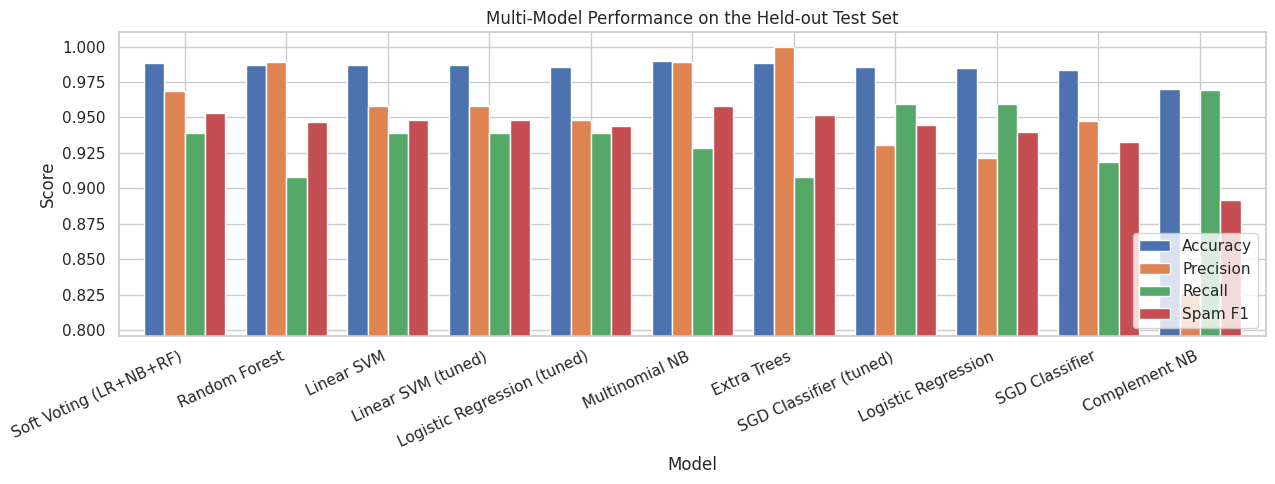

In [13]:
metric_cols = ["Accuracy", "Precision", "Recall", "Spam F1"]
plot_df = results_df.set_index("Model")[metric_cols]
lo = max(0.0, plot_df.min().min() - 0.03)

plot_df.plot(kind="bar", figsize=(13, 5), ylim=(lo, 1.01), width=0.8)
plt.title("Multi-Model Performance on the Held-out Test Set")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. ROC / PR curves and detailed evaluation of the best model

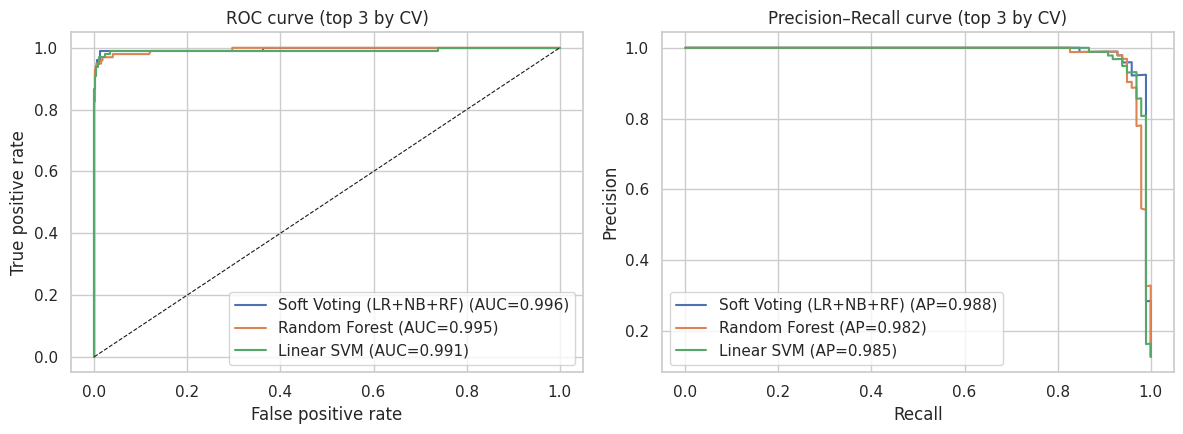

In [14]:
top3 = results_df["Model"].head(3).tolist()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name in top3:
    s = get_scores(fitted[name], test_df)
    fpr, tpr, _ = roc_curve(test_df["label"], s)
    prec, rec, _ = precision_recall_curve(test_df["label"], s)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(test_df['label'], s):.3f})")
    ax[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(test_df['label'], s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title="ROC curve (top 3 by CV)", xlabel="False positive rate", ylabel="True positive rate")
ax[1].set(title="Precision–Recall curve (top 3 by CV)", xlabel="Recall", ylabel="Precision")
ax[0].legend(loc="lower right"); ax[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

Best model: Soft Voting (LR+NB+RF)
              precision    recall  f1-score   support

         Ham     0.9912    0.9956    0.9934       678
        Spam     0.9684    0.9388    0.9534        98

    accuracy                         0.9884       776
   macro avg     0.9798    0.9672    0.9734       776
weighted avg     0.9883    0.9884    0.9883       776



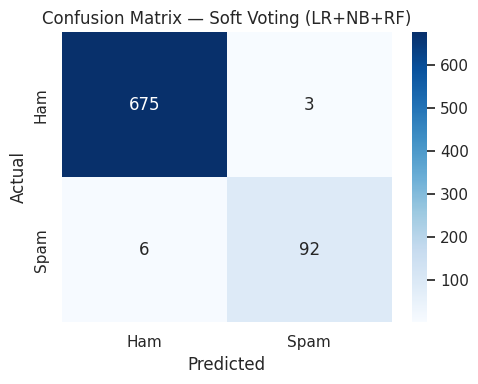

In [15]:
best_model = fitted[best_model_name]
best_pred = best_model.predict(test_df)

print("Best model:", best_model_name)
print(classification_report(test_df["label"], best_pred, target_names=["Ham", "Spam"], digits=4))

cm = confusion_matrix(test_df["label"], best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Interpretation and error analysis



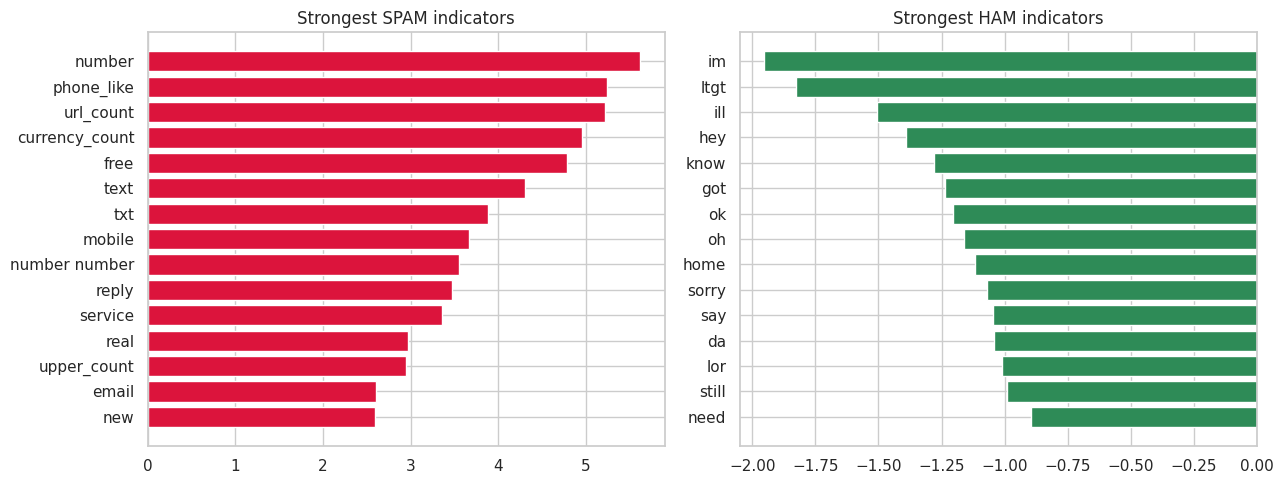

In [16]:
lr_pipe = fitted["Logistic Regression"]
feat_names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["prep"].get_feature_names_out()]
coef = lr_pipe.named_steps["clf"].coef_[0]
order = np.argsort(coef)
top_spam = [(feat_names[i], coef[i]) for i in order[::-1][:15]]
top_ham = [(feat_names[i], coef[i]) for i in order[:15]]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh([w for w, _ in top_spam][::-1], [c for _, c in top_spam][::-1], color="crimson")
ax[0].set_title("Strongest SPAM indicators")
ax[1].barh([w for w, _ in top_ham][::-1], [c for _, c in top_ham][::-1], color="seagreen")
ax[1].set_title("Strongest HAM indicators")
plt.tight_layout()
plt.show()

In [17]:
err = test_df.assign(pred=best_pred)
fp = err[(err["label"] == 0) & (err["pred"] == 1)]
fn = err[(err["label"] == 1) & (err["pred"] == 0)]

pd.set_option("display.max_colwidth", 160)
print(f"False positives (ham flagged as spam): {len(fp)}")
display(fp[["message"]].head(10))
print(f"False negatives (spam that slipped through): {len(fn)}")
display(fn[["message"]].head(10))

False positives (ham flagged as spam): 3


,message
2188,Hmm...Bad news...Hype park plaza $700 studio taken...Only left 2 bedrm-$900...
2888,Your bill at 3 is å£33.65 so thats not bad!
1252,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May"


False negatives (spam that slipped through): 6


,message
4220,Money i have won wining number 946 wot do i do next
2641,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
3634,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg å£1.50"
4497,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
3741,ringtoneking 84484
849,Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r


## 11. Prediction function (classical ML)



In [18]:
final_model = fitted[best_model_name]

def build_frame(texts):
    texts = list(texts)
    base = pd.DataFrame({"message": texts, "clean_message": [clean_text(t) for t in texts]})
    return pd.concat([base, pd.DataFrame([extract_features(t) for t in texts])], axis=1)

def ml_predict(texts, model=None):
    model = model or final_model
    frame = build_frame(texts)
    return model.predict(frame), get_scores(model, frame)

def predict_sms(text):
    label, score = ml_predict([text])
    return "SPAM" if label[0] == 1 else "HAM"

examples = [
    "Congratulations! You have won a free iPhone. Click here now!",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! Claim your cash prize by calling 09012345678 now!",
]
for msg in examples:
    print(f"{predict_sms(msg):5s} -> {msg}")

HAM   -> Congratulations! You have won a free iPhone. Click here now!
HAM   -> Hi, are we meeting tomorrow at 3 PM?
SPAM  -> URGENT! Claim your cash prize by calling 09012345678 now!


## 12. Save the trained system


In [19]:
deploy_model = clone(final_model).fit(dev_df, dev_df["label"])

artifact = {
    "model_name": best_model_name,
    "pipeline": deploy_model,
    "selected_features": best_subset,
    "all_features": feature_names,
    "note": "Input is a DataFrame built by build_frame(): columns message, clean_message + handcrafted features.",
}
joblib.dump(artifact, "sms_spam_backtracking_model.joblib")
results_df.to_csv("model_comparison.csv", index=False)
bt_df.sort_values(["val_f1", "size"], ascending=[False, True]).to_csv("backtracking_search_log.csv", index=False)

print("Saved: sms_spam_backtracking_model.joblib")
print("Saved: model_comparison.csv")
print("Saved: backtracking_search_log.csv")

Saved: sms_spam_backtracking_model.joblib
Saved: model_comparison.csv
Saved: backtracking_search_log.csv


## 13. LLM-based spam detection

In [20]:
import anthropic
from anthropic import Anthropic

def get_api_key():
    try:
        from google.colab import userdata
        key = userdata.get("ANTHROPIC_API_KEY")
        if key:
            return key
    except Exception:
        pass
    return os.environ.get("ANTHROPIC_API_KEY") or getpass.getpass(
        "Anthropic API key (press Enter to skip the LLM sections): ")

api_key = get_api_key()
RUN_LLM = bool(api_key)

# Good accuracy/cost balance. For a cheaper, faster run use "claude-haiku-5-5".
LLM_MODEL = "claude-sonnet-5-5"
LLM_SAMPLE_SIZE = 300      # test messages sent to the LLM (set to len(test_df) for the full test set)
LLM_WORKERS = 8            # parallel API calls

client = Anthropic(api_key=api_key, max_retries=4) if RUN_LLM else None
print("LLM sections enabled." if RUN_LLM else "No API key — LLM sections will be skipped.")

Anthropic API key (press Enter to skip the LLM sections): ··········
No API key — LLM sections will be skipped.


In [21]:
SYSTEM_PROMPT = """You are an expert SMS spam filter.

SPAM = unsolicited or deceptive messages: prize/lottery/competition claims, "you have won",
premium-rate or short-code numbers, "text STOP to opt out", paid subscriptions, ringtone/offer ads,
dating/chat-line promotions, phishing, urgent account or payment threats, or a request to call/text
a number to claim something.
HAM = normal personal or informational messages: friends, family, work, plans, short chat in
casual or abbreviated English, genuine reminders.

Reply with ONLY one JSON object and nothing else:
{"label": "SPAM" or "HAM", "confidence": a number from 0 to 1, "reason": "max 15 words"}"""

def _one_line(text, limit=250):
    return str(text).replace("\n", " ").strip()[:limit]

# Few-shot examples come from the TRAINING set only (never from test).
fs_spam = train_df[train_df["label"] == 1].sample(5, random_state=RANDOM_STATE)["message"].tolist()
fs_ham = train_df[train_df["label"] == 0].sample(5, random_state=RANDOM_STATE)["message"].tolist()
FEW_SHOT_BLOCK = "Labelled examples:\n" + "\n".join(
    [f'- "{_one_line(m)}" -> SPAM' for m in fs_spam] +
    [f'- "{_one_line(m)}" -> HAM' for m in fs_ham]
)

def build_prompt(text, mode):
    head = FEW_SHOT_BLOCK + "\n\n" if mode == "few_shot" else ""
    return f'{head}Classify this SMS:\n"""{_one_line(text, 1000)}"""'

def parse_llm(text):
    """Return (label 1/0/None, confidence, reason)."""
    m = re.search(r"\{.*?\}", text, flags=re.S)
    if m:
        try:
            obj = json.loads(m.group(0))
            lab = str(obj.get("label", "")).strip().upper()
            if lab in ("SPAM", "HAM"):
                return (1 if lab == "SPAM" else 0,
                        float(obj.get("confidence", np.nan)),
                        str(obj.get("reason", ""))[:200])
        except Exception:
            pass
    up = text.upper()
    if "SPAM" in up and "HAM" not in up:
        return 1, np.nan, text[:200]
    if "HAM" in up and "SPAM" not in up:
        return 0, np.nan, text[:200]
    return None, np.nan, text[:200]

llm_cache = {}
usage = {"calls": 0, "input_tokens": 0, "output_tokens": 0}
usage_lock = threading.Lock()

def llm_classify(text, mode="zero_shot"):
    key = (mode, text)
    if key in llm_cache:
        return llm_cache[key]
    for attempt in range(4):
        try:
            resp = client.messages.create(
                model=LLM_MODEL,
                max_tokens=150,
                system=SYSTEM_PROMPT,
                messages=[{"role": "user", "content": build_prompt(text, mode)}],
            )
            out_text = "".join(b.text for b in resp.content if getattr(b, "type", "") == "text")
            with usage_lock:
                usage["calls"] += 1
                usage["input_tokens"] += resp.usage.input_tokens
                usage["output_tokens"] += resp.usage.output_tokens
            result = parse_llm(out_text)
            llm_cache[key] = result
            return result
        except Exception as e:
            err = str(e)[:120]
            time.sleep(2 ** attempt)
    return (None, np.nan, f"API error: {err}")

def run_llm(texts, mode):
    texts = list(texts)
    with ThreadPoolExecutor(max_workers=LLM_WORKERS) as ex:
        results = list(tqdm(ex.map(lambda t: llm_classify(t, mode), texts),
                            total=len(texts), desc=f"LLM {mode}"))
    out = pd.DataFrame(results, columns=["pred", "confidence", "reason"])
    failed = int(out["pred"].isna().sum())
    if failed:
        print(f"WARNING: {failed} call(s) failed or were unparseable; counted as HAM.")
    out["pred"] = out["pred"].fillna(0).astype(int)
    return out

if RUN_LLM:
    print("Smoke test:", llm_classify("WINNER!! You have won a 1000 prize. Call 09061701461 now!"))

### 13.1 Run the LLM on a stratified sample of the test set


In [22]:
if RUN_LLM:
    n = min(LLM_SAMPLE_SIZE, len(test_df) - 2)
    llm_sample, _ = train_test_split(test_df, train_size=n, stratify=test_df["label"],
                                     random_state=RANDOM_STATE)
    y_s = llm_sample["label"].values
    print(f"Sample: {len(llm_sample)} messages | spam = {y_s.mean():.1%}")

    zs = run_llm(llm_sample["message"], "zero_shot")
    fs = run_llm(llm_sample["message"], "few_shot")

    print(f"\nAPI calls: {usage['calls']} | input tokens: {usage['input_tokens']:,} | "
          f"output tokens: {usage['output_tokens']:,}")
else:
    print("Skipped (no API key).")

Skipped (no API key).


### 13.2 Hybrid cascade: ML first, LLM only when unsure



In [23]:
LOW, HIGH = 0.15, 0.85      # uncertainty band

if RUN_LLM:
    prob_names = [n for n in results_df["Model"] if hasattr(fitted[n], "predict_proba")]
    prob_name = prob_names[0]                      # best (by CV) model that outputs probabilities
    prob_model = fitted[prob_name]

    p_spam = prob_model.predict_proba(llm_sample)[:, 1]
    uncertain = (p_spam > LOW) & (p_spam < HIGH)
    cascade_pred = np.where(uncertain, fs["pred"].values, (p_spam >= 0.5).astype(int))

    print(f"Cascade ML model        : {prob_name}")
    print(f"Uncertain messages      : {uncertain.sum()} of {len(llm_sample)} "
          f"({uncertain.mean():.1%}) -> sent to the LLM")
    print(f"LLM calls saved vs. LLM-only: {1 - uncertain.mean():.1%}")
else:
    print("Skipped (no API key).")

Skipped (no API key).


### 13.3 Final comparison: ML vs LLM vs Hybrid (same messages)

In [24]:
def metric_row(name, y_true, y_pred, llm_calls):
    return {
        "Approach": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Spam F1": f1_score(y_true, y_pred, zero_division=0),
        "LLM calls": llm_calls,
    }

if RUN_LLM:
    ml_best_pred = fitted[best_model_name].predict(llm_sample)
    cmp_df = pd.DataFrame([
        metric_row(f"ML — {best_model_name}", y_s, ml_best_pred, 0),
        metric_row(f"LLM zero-shot ({LLM_MODEL})", y_s, zs["pred"].values, len(llm_sample)),
        metric_row(f"LLM few-shot ({LLM_MODEL})", y_s, fs["pred"].values, len(llm_sample)),
        metric_row("Hybrid: ML → LLM cascade", y_s, cascade_pred, int(uncertain.sum())),
    ])
    display(cmp_df.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "Spam F1"]}))

    cmp_df.set_index("Approach")[["Accuracy", "Precision", "Recall", "Spam F1"]].plot(
        kind="bar", figsize=(11, 4.5), width=0.8,
        ylim=(max(0, cmp_df[["Precision", "Recall", "Spam F1"]].min().min() - 0.05), 1.01))
    plt.title(f"ML vs LLM vs Hybrid on the same {len(llm_sample)} test messages")
    plt.xticks(rotation=15, ha="right")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped (no API key).")

Skipped (no API key).


In [25]:
# Where do the ML model and the few-shot LLM disagree? (the most interesting cases)
if RUN_LLM:
    show = llm_sample[["message", "label"]].copy()
    show["ML"] = ml_best_pred
    show["LLM"] = fs["pred"].values
    show["LLM_conf"] = fs["confidence"].values
    show["LLM_reason"] = fs["reason"].values
    dis = show[show["ML"] != show["LLM"]]
    lab = {0: "ham", 1: "spam"}
    dis = dis.assign(label=dis["label"].map(lab), ML=dis["ML"].map(lab), LLM=dis["LLM"].map(lab))
    print(f"Disagreements: {len(dis)} of {len(show)}")
    display(dis.head(15).reset_index(drop=True))
else:
    print("Skipped (no API key).")

Skipped (no API key).


In [26]:
# Live demo: ML (with probability) vs LLM (with reasoning)
demo = examples + [
    "Hey, can you send me the notes from today's class? Thanks!",
    "FREE entry! Text WIN to 80086 to receive your prize. T&Cs apply. 18+ only",
    "Your parcel could not be delivered. Pay the 1.99 fee at http://bit.ly/x1y2 to reschedule.",
    "Ok see you at the station at 6, I'll bring the tickets",
]

ml_labels, ml_scores = ml_predict(demo)
for msg, ml_l in zip(demo, ml_labels):
    line = f"ML : {'SPAM' if ml_l == 1 else 'HAM':4s}"
    if RUN_LLM:
        l, conf, reason = llm_classify(msg, "few_shot")
        line += f" | LLM: {'SPAM' if l == 1 else 'HAM':4s} (conf {conf:.2f}) — {reason}"
    print(line, "\n    ->", msg, "\n")

ML : HAM  
    -> Congratulations! You have won a free iPhone. Click here now! 

ML : HAM  
    -> Hi, are we meeting tomorrow at 3 PM? 

ML : SPAM 
    -> URGENT! Claim your cash prize by calling 09012345678 now! 

ML : HAM  
    -> Hey, can you send me the notes from today's class? Thanks! 

ML : SPAM 
    -> FREE entry! Text WIN to 80086 to receive your prize. T&Cs apply. 18+ only 

ML : SPAM 
    -> Your parcel could not be delivered. Pay the 1.99 fee at http://bit.ly/x1y2 to reschedule. 

ML : HAM  
    -> Ok see you at the station at 6, I'll bring the tickets 



### 13.4 (Optional) Free open-source alternative — no API key



In [27]:
RUN_HF_ZEROSHOT = False      # set True to try it (downloads ~1.6 GB model)
HF_SAMPLE_SIZE = 200

if RUN_HF_ZEROSHOT:
    !pip -q install transformers torch
    from transformers import pipeline
    import torch

    hf = pipeline("zero-shot-classification", model="facebook/bart-large-mnli",
                  device=0 if torch.cuda.is_available() else -1)
    labels = ["spam or advertising or scam message", "normal personal message"]

    hf_sample, _ = train_test_split(test_df, train_size=min(HF_SAMPLE_SIZE, len(test_df) - 2),
                                    stratify=test_df["label"], random_state=RANDOM_STATE)
    hf_pred = []
    for text in tqdm(hf_sample["message"].tolist(), desc="BART zero-shot"):
        out = hf(text, candidate_labels=labels)
        hf_pred.append(1 if out["labels"][0] == labels[0] else 0)

    hf_true = hf_sample["label"].values
    ml_on_hf = fitted[best_model_name].predict(hf_sample)
    display(pd.DataFrame([
        metric_row(f"ML — {best_model_name}", hf_true, ml_on_hf, 0),
        metric_row("BART-MNLI zero-shot (free)", hf_true, np.array(hf_pred), 0),
    ]).drop(columns="LLM calls").style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "Spam F1"]}))
else:
    print("Skipped (RUN_HF_ZEROSHOT = False).")

Skipped (RUN_HF_ZEROSHOT = False).
